# 11.4 Ловушки A/B-тестов — код страницы

Аналитика 101 · блок «Дата аналитика» · тема 11 «A/B-тестирование» · страница 11.4.

В ноутбуке четыре блока кода страницы: симуляция подглядывания на 20 000 A/A-тестов, поправки на множественность в statsmodels, проверка SRM хи-квадратом и эффект по суткам с первого показа с графиком новизны. Данные учебные: эксперименты из общего набора темы `data/ab/`.

**Как работать.** Выполняйте ячейки по порядку сверху вниз. Блоки независимы: каждый сам читает данные. Первый блок держит в памяти около 100 МБ.

Вывод получен на Python 3.13, pandas 3.0, NumPy 2.5, SciPy 1.18, statsmodels 0.15 и matplotlib 3.10.

## Где лежат данные

Код страницы читает файлы по пути от корня папки с материалами: `data/ab/exposures.csv`, `users.csv` и `sessions.parquet`. Ноутбук лежит в папке страницы, поэтому первая ячейка поднимается до папки, в которой есть `data/`, и делает её рабочей. Туда же последний блок сохранит рисунок `novelty.svg`.

In [1]:
import os
import pathlib
import platform

import matplotlib
import numpy as np
import pandas as pd
import scipy
import statsmodels

root = pathlib.Path.cwd()
while not (root / "data" / "ab").is_dir() and root != root.parent:
    root = root.parent                      # поднимаемся, пока рядом не окажется data/ab/
assert (root / "data" / "ab" / "sessions.parquet").exists(), \
    "Не найдена папка data/ab/. Скачайте общий набор темы 11 и положите data/ рядом с папкой страницы"
os.chdir(root)

print("Python", platform.python_version(), "| pandas", pd.__version__, "| NumPy", np.__version__, "| SciPy", scipy.__version__,
      "| statsmodels", statsmodels.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.18 | pandas 3.0.5 | NumPy 2.5.3 | SciPy 1.18.1 | statsmodels 0.15.0 | matplotlib 3.10.0


## Код: симуляция подглядывания

Те же зерно и порядок вызовов, что в общем генераторе `data/ab/aa_sim.py`: это те же 20 000 A/A-тестов, что за интерактивами страниц 11.4 и 11.5.

### Симуляция подглядывания: 20 000 A/A-тестов

In [2]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(1104)
RUNS, DAYS, N, P, M = 20_000, 28, 1_000, 0.14, 10    # 20 000 A/A-тестов по 28 дней, 10 метрик в каждом
# покупки за день: тест × метрика × день; обе группы из одного распределения — эффекта нет
a = rng.binomial(N, P, (RUNS, M, DAYS)).cumsum(-1)
b = rng.binomial(N, P, (RUNS, M, DAYS)).cumsum(-1)
n = N * np.arange(1, DAYS + 1)                       # людей в группе к концу дня
pool = (a + b) / (2 * n)
z = (b - a) / n / np.sqrt(pool * (1 - pool) * 2 / n)  # z-тест для двух долей по накопленным данным
sig = 2 * stats.norm.sf(np.abs(z)) < 0.05            # где p < 0,05


def false_wins(k, m=1):
    """Доля тестов, где хотя бы одна из m метрик хотя бы в один из k взглядов дала p < 0,05."""
    look = [-(-DAYS * j // k) for j in range(1, k + 1)]   # дни взглядов: ceil(28·j/k), при k = 4 — 7, 14, 21, 28
    return sig[:, :m][:, :, [d - 1 for d in look]].any(axis=(1, 2)).mean()


for k in (1, 2, 4, 7, 14, 28):
    print(f"взглядов {k:>2}, одна метрика: ложных побед {false_wins(k):.1%}")
for m in (3, 5, 10):
    print(f"метрик {m:>2}: один взгляд {false_wins(1, m):.1%}, каждый день {false_wins(28, m):.1%}")

взглядов  1, одна метрика: ложных побед 5.1%
взглядов  2, одна метрика: ложных побед 8.8%
взглядов  4, одна метрика: ложных побед 13.0%
взглядов  7, одна метрика: ложных побед 17.1%
взглядов 14, одна метрика: ложных побед 22.6%
взглядов 28, одна метрика: ложных побед 28.0%
метрик  3: один взгляд 14.2%, каждый день 62.3%
метрик  5: один взгляд 22.7%, каждый день 80.3%
метрик 10: один взгляд 39.7%, каждый день 96.0%


Те же seed и порядок вызовов, что в общем генераторе data/ab/aa_sim.py, поэтому доли совпадают с интерактивом. Метрики независимы: настоящие метрики теста связаны, и раздувание у них меньше.

## Код: поправки на множественность

### Поправки на множественность в statsmodels

In [3]:
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportions_ztest

ex = pd.read_csv("data/ab/exposures.csv")
users = pd.read_csv("data/ab/users.csv", dtype={"app_version": str})
ses = pd.read_parquet("data/ab/sessions.parquet")
BOTS = ["u_025389", "u_053191", "u_055948"]


def per_user(exp):
    """Строка на участника: группа из exposures, сегмент «платформа · страна», метрики за тест; без ботов."""
    m = ses[ses.experiment == exp].groupby("user_id").agg(conv=("converted", "max"), orders=("orders", "sum"),
                                                          revenue=("revenue", "sum"), sessions=("session_id", "size"))
    u = ex[(ex.experiment == exp) & ~ex.user_id.isin(BOTS)].merge(m, on="user_id").merge(users, on="user_id")
    u["segment"] = u.platform + " · " + u.country
    return u


def conv_p(g):                                        # z-тест для долей: конверсия B против A
    t = g.groupby("group").conv.agg(["sum", "size"])
    return proportions_ztest(t["sum"], t["size"])[1]


def correct(p):
    t = pd.DataFrame({"p": p})
    for method in ("bonferroni", "holm", "fdr_bh"):  # FWER, FWER, FDR
        t[method] = multipletests(t.p, alpha=0.05, method=method)[1]   # скорректированные p
    return t.sort_values("p")


# 1. A/A-тест, 12 сегментов: эффекта нет нигде
aa = correct({s: conv_p(g) for s, g in per_user("aa_check").groupby("segment")})
print(aa.head(3).round(4).to_string(), "\n")
print("A/A, значимых при 0,05:", (aa < 0.05).sum().to_dict(), "\n")

# 2. checkout_v2: 4 метрики на человека и конверсия в 12 сегментах — 16 гипотез одного отчёта
u = per_user("checkout_v2")
hyp = {"конверсия": conv_p(u)}
for met, name in (("orders", "заказы"), ("revenue", "выручка"), ("sessions", "сессии")):   # t-тест Уэлча
    hyp[name] = stats.ttest_ind(u[u.group == "B"][met], u[u.group == "A"][met], equal_var=False).pvalue
hyp |= {"сегмент " + s: conv_p(g) for s, g in u.groupby("segment")}
chk = correct(hyp)
print(chk.head(6).round(4).to_string(), "\n")
print("checkout_v2, значимых при 0,05:", (chk < 0.05).sum().to_dict())

                   p  bonferroni    holm  fdr_bh
web · KZ      0.0290      0.3479  0.3479  0.3479
ios · BY      0.1757      1.0000  1.0000  0.6003
android · BY  0.2476      1.0000  1.0000  0.6003 

A/A, значимых при 0,05: {'p': 1, 'bonferroni': 0, 'holm': 0, 'fdr_bh': 0} 



                           p  bonferroni    holm  fdr_bh
конверсия             0.0001      0.0013  0.0013  0.0013
заказы                0.0006      0.0099  0.0093  0.0050
сегмент web · RU      0.0053      0.0848  0.0742  0.0283
сегмент ios · BY      0.0446      0.7144  0.5804  0.1465
сегмент ios · KZ      0.0458      0.7325  0.5804  0.1465
сегмент android · KZ  0.1401      1.0000  1.0000  0.3495 

checkout_v2, значимых при 0,05: {'p': 5, 'bonferroni': 2, 'holm': 2, 'fdr_bh': 3}


multipletests возвращает четыре объекта, [1] — скорректированные p: их сравнивают с 0,05. holm — метод Холма: та же гарантия FWER, что у Бонферрони, но чуть мягче. В таблице checkout_v2 показаны 6 гипотез из 16 с самыми маленькими p.

## Код: проверка SRM

Здесь считаются все показы, вместе с ботами: проверка ищет поломку разбиения и логирования, а не эффект.

### Проверка SRM хи-квадратом

In [4]:
import pandas as pd
from scipy.stats import chisquare

ex = pd.read_csv("data/ab/exposures.csv")
users = pd.read_csv("data/ab/users.csv", dtype={"app_version": str}, keep_default_na=False)

# план — 50/50, поэтому ожидание по умолчанию: поровну
for exp, g in ex.groupby("experiment"):
    n = g.group.value_counts().sort_index()
    print(f"{exp:<12} A {n['A']:>6}  B {n['B']:>6}  доля B {n['B'] / n.sum():.2%}  p = {chisquare(n).pvalue:.2g}")

# где сидит перекос в reco_block: та же проверка по платформе и версии приложения
reco = ex[ex.experiment == "reco_block"].merge(users, on="user_id")
print()
for seg, g in reco.groupby(reco.platform + " " + reco.app_version):
    n = g.group.value_counts().sort_index()
    print(f"{seg:<14} A {n['A']:>5}  B {n['B']:>5}  доля B {n['B'] / n.sum():.1%}  p = {chisquare(n).pvalue:.2g}")

aa_check     A  19988  B  20092  доля B 50.13%  p = 0.6
checkout_v2  A  28440  B  28360  доля B 49.93%  p = 0.74
reco_block   A  24440  B  23746  доля B 49.28%  p = 0.0016

android 3.1.4  A  2782  B  1971  доля B 41.5%  p = 6e-32
android 3.3.0  A  8383  B  8250  доля B 49.6%  p = 0.3
ios 3.3.0      A  6097  B  6120  доля B 50.1%  p = 0.84
web            A  7178  B  7405  доля B 50.8%  p = 0.06


Считаются все показы, вместе с ботами: проверка ищет поломку разбиения и логирования, а не эффект. У сайта версии приложения нет, поэтому сегмент называется просто web.

## Код: эффект по суткам с первого показа и график новизны

### Эффект по дням с первого показа и график новизны

In [5]:
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ex = pd.read_csv("data/ab/exposures.csv", parse_dates=["exposed_at"])
ses = pd.read_parquet("data/ab/sessions.parquet")
BOTS = ["u_025389", "u_053191", "u_055948"]
s = (ses[(ses.experiment == "checkout_v2") & ~ses.user_id.isin(BOTS)].drop(columns="group")   # группа — из exposures
     .merge(ex[ex.experiment == "checkout_v2"][["user_id", "group", "exposed_at"]], on="user_id"))
s["day"] = (s.session_start - s.exposed_at) // pd.Timedelta(days=1)        # полных суток с первого показа
s["week"] = ((s.session_start + pd.Timedelta(hours=3)).dt.floor("D").dt.tz_localize(None)
             - pd.Timestamp("2026-09-07")).dt.days // 7 + 1                 # календарная неделя теста, день минский


def uplift(g):
    """Эффект конверсии сессии B к A и 95-% интервал: дельта-метод по пользователям, как в 11.3."""
    r = {}
    for grp, x in g.groupby("group"):
        u = x.groupby("user_id").converted.agg(["sum", "size"])
        R = u["sum"].sum() / u["size"].sum()
        r[grp] = R, (u["sum"] - R * u["size"]).var() / len(u) / u["size"].mean() ** 2
    (ra, va), (rb, vb) = r["A"], r["B"]
    lr, se = np.log(rb / ra), np.sqrt(va / ra ** 2 + vb / rb ** 2)
    return pd.Series({"A": ra, "B": rb, "эффект": np.expm1(lr), "от": np.expm1(lr - 1.96 * se), "до": np.expm1(lr + 1.96 * se)})


BINS = [(0, 2), (3, 6), (7, 13), (14, 27)]
by_day = pd.DataFrame({f"{a}–{b}": uplift(s[s.day.between(a, b)]) for a, b in BINS}).T
by_week = pd.DataFrame({f"неделя {w}": uplift(g) for w, g in s.groupby("week")}).T
total = uplift(s)
print("по дням с показа:\n", (by_day * 100).round(1).to_string(), sep="")
print("по календарным неделям:\n", (by_week * 100).round(1).to_string(), sep="")
print(f"за 28 дней: {total['эффект']:+.1%} [{total['от']:+.1%}; {total['до']:+.1%}]")

# график по правилам 8.4: заголовок-вывод, один акцент, подписи на месте
plt.rcParams.update({"svg.fonttype": "none", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
ACC, GREY, MUT = "#0d7468", "#9aa3b2", "#737c8f"
pct = lambda v: f"{v * 100:+.1f}%".replace(".", ",").replace("-", "−")
fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
for (a, b), (_, r) in zip(BINS, by_day.iterrows()):
    ax.fill_between([a, b + 1], r["от"] * 100, r["до"] * 100, color=ACC, alpha=0.13, linewidth=0)
    ax.plot([a, b + 1], [r["эффект"] * 100] * 2, color=ACC, linewidth=2.6)
    ax.annotate(pct(r["эффект"]), ((a + b + 1) / 2, r["эффект"] * 100), xytext=(0, 6),
                textcoords="offset points", ha="center", color=ACC, fontweight="bold")
t = np.linspace(0, 28, 200)
ax.plot(t, (0.04 + 0.20 * np.exp(-t / 5)) * 100, color=GREY, linestyle="--", linewidth=1.4)
ax.annotate("так данные сгенерированы:\n+4% навсегда плюс новизна", (2.4, 16.4), xytext=(7.6, 27), color=MUT,
            fontsize=8.5, arrowprops={"arrowstyle": "-", "color": GREY, "linewidth": 0.8})
ax.axhline(total["эффект"] * 100, color=MUT, linewidth=1, linestyle=":")
ax.annotate(f"оценка за 28 дней {pct(total['эффект'])}", (27.8, total["эффект"] * 100 + 1),
            ha="right", color=MUT, fontsize=8.5)
ax.axhline(0, color="#454f62", linewidth=0.8)
ax.set(xlim=(0, 28), ylim=(-12, 36), xticks=[0, 3, 7, 14, 21, 28])
ax.set_yticks([-10, 0, 10, 20, 30], labels=["−10%", "0", "+10%", "+20%", "+30%"])
ax.set_xlabel("дней с первого показа · учебные данные checkout_v2, 7 сентября — 4 октября 2026", loc="left",
              fontsize=8, color=GREY)
fig.suptitle("Прирост конверсии от нового оформления тает за неделю после показа", x=0.01, ha="left",
             fontweight="bold", fontsize=11.5)
ax.set_title("Конверсия сессии B к A по дням с первого показа, 95-% интервалы", loc="left", fontsize=8.5, color=MUT)
fig.savefig("novelty.svg")

по дням с показа:
         A    B  эффект    от    до
0–2    3.7  4.5    21.8  14.1  30.1
3–6    3.8  4.1     8.9  -1.2  20.0
7–13   3.7  4.1    11.0   2.3  20.5
14–27  3.8  3.8    -0.3  -7.3   7.3
по календарным неделям:
            A    B  эффект    от    до
неделя 1  3.7  4.4    21.1  12.0  31.0
неделя 2  3.8  4.1     6.7  -1.2  15.3
неделя 3  3.8  4.1     6.7  -1.2  15.2
неделя 4  3.6  3.9     8.0   0.1  16.5
за 28 дней: +10.4% [+5.5%; +15.5%]


Интервал относительного эффекта — дельта-метод для логарифма отношения конверсий сессий по пользователям, как в 11.3. Пунктир на графике есть только у учебных данных: в жизни истинный эффект неизвестен.

Блок графика переключает Matplotlib на вывод в файл, поэтому под ячейкой рисунка нет. Показываем сохранённый файл.

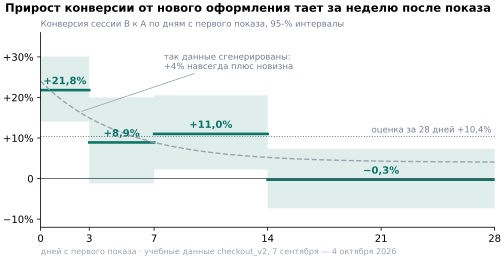

In [6]:
from IPython.display import SVG, display

display(SVG("novelty.svg"))